In [1]:
import sys
import glob

sys.path.insert(0, "/opt/spark/python")
sys.path.insert(0, glob.glob("/opt/spark/python/lib/py4j*.zip")[0])

from pyspark.sql import SparkSession
from graphframes import GraphFrame

In [11]:
%pip install networkx

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os

os.environ["HOME"] = "/tmp"

spark = (
    SparkSession.builder
    .appName("Graph Analytics - Reviewer Produk")
    .master("local[4]")
    .config("spark.jars.packages", "io.graphframes:graphframes-spark4_2.13:0.12.3")
    .config("spark.jars.ivy", "/tmp/.ivy2")
    .config("spark.driver.memory", "5g")
    .config("spark.driver.maxResultSize", "2g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.hadoop.dfs.replication", "1")
    .getOrCreate()
)

:: loading settings :: url = jar:file:/opt/spark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /tmp/.ivy2/cache
The jars for the packages stored in: /tmp/.ivy2/jars
io.graphframes#graphframes-spark4_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-3e38c340-3cec-476d-bcac-7bb6cfd2295d;1.0
	confs: [default]
	found io.graphframes#graphframes-spark4_2.13;0.12.3 in central
	found io.graphframes#graphframes-graphx-spark4_2.13;0.12.3 in central
	found org.apache.datasketches#datasketches-java;6.2.0 in central
	found org.apache.datasketches#datasketches-memory;3.0.2 in central
:: resolution report :: resolve 343ms :: artifacts dl 10ms
	:: modules in use:
	io.graphframes#graphframes-graphx-spark4_2.13;0.12.3 from central in [default]
	io.graphframes#graphframes-spark4_2.13;0.12.3 from central in [default]
	org.apache.datasketches#datasketches-java;6.2.0 from central in [default]
	org.apache.datasketches#dat

In [3]:
spark.sparkContext._jsc.sc().listJars()

JavaObject id=o45

In [4]:
import os
print(os.environ.get("PYSPARK_SUBMIT_ARGS"))
print(os.environ.get("HOME"))

None
/tmp


### Test dulu GraphFrame

In [5]:
from graphframes import GraphFrame

vertices = spark.createDataFrame(
    [
        ("A", "Acep"),
        ("B", "Budi"),
        ("C", "Caca")
    ],
    ["id", "name"]
)

edges = spark.createDataFrame(
    [
        ("A", "B", "friend"),
        ("B", "C", "friend")
    ],
    ["src", "dst", "relationship"]
)

g = GraphFrame(vertices, edges)

g.vertices.show()

+---+----+
| id|name|
+---+----+
|  A|Acep|
|  B|Budi|
|  C|Caca|
+---+----+



### Start GraphFrame 

In [ ]:
from pyspark.sql import functions as F
from graphframes import GraphFrame

spark.sparkContext.setCheckpointDir("hdfs://namenode:9000/tmp/checkpoint")  # wajib untuk beberapa algoritma

In [7]:
df = spark.read.parquet("hdfs://namenode:9000/data/amazon_reviews/final_reviews_parquet")
df.select("reviewerID","asin","overall","vote","verified","review_datetime").printSchema()

root
 |-- reviewerID: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- overall: double (nullable = true)
 |-- vote: integer (nullable = true)
 |-- verified: boolean (nullable = true)
 |-- review_datetime: string (nullable = true)



### Plus Atribut

In [21]:
edges_raw = (df.groupBy("reviewerID", "asin")
    .agg(F.count("*").alias("n_reviews"),
         F.avg("overall").alias("avg_rating"),
         F.sum("vote").alias("total_vote"),
         F.max("review_datetime").alias("last_review")))

26/11/05 19:03:56 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


### Penyaringan soalnya banyak banget jadi dikecilin aja (soalnya lebih untuk nyari insight)

In [22]:
# User minimal 2 produk berbeda
u_ok = edges_raw.groupBy("reviewerID").count().filter("count >= 2").select("reviewerID")
e1 = edges_raw.join(u_ok, "reviewerID")

# Produk minimal 5 reviewer (dari sisa edge)
p_ok = e1.groupBy("asin").count().filter("count >= 5").select("asin")
edges_f = e1.join(p_ok, "asin")

print(edges_raw.count(), "->", edges_f.count())

2487171 -> 1265895


### Pembuatan tabel vertex dan edges

In [23]:
meta = df.select("asin","title","brand").dropDuplicates(["asin"])

users = (edges_f.select("reviewerID").distinct()
    .select(F.concat(F.lit("U_"), "reviewerID").alias("id"),
            F.lit("user").alias("type"),
            F.lit(None).cast("string").alias("title"),
            F.lit(None).cast("string").alias("brand")))

prods = (edges_f.select("asin").distinct().join(meta, "asin")
    .select(F.concat(F.lit("P_"), "asin").alias("id"),
            F.lit("product").alias("type"), "title", "brand"))

vertices = users.unionByName(prods)

edges = edges_f.select(
    F.concat(F.lit("U_"), "reviewerID").alias("src"),
    F.concat(F.lit("P_"), "asin").alias("dst"),
    "n_reviews", "avg_rating", "total_vote")

g = GraphFrame(vertices, edges)

### Graph Stat

In [12]:
n_users = users.count(); n_prods = prods.count(); n_edges = edges.count()
density = n_edges / (n_users * n_prods)   # density bipartit
print(n_users, n_prods, n_edges, density)

378040 28271 1265895 0.00011844555286158045


### Degree

In [13]:
prod_deg = edges.groupBy("dst").agg(F.count("*").alias("n_reviewers"),
                                    F.sum("total_vote").alias("votes"),
                                    F.avg("avg_rating").alias("mean_rating"))
user_deg = edges.groupBy("src").agg(F.count("*").alias("n_products"),
                                    F.sum("total_vote").alias("votes"),
                                    F.avg("avg_rating").alias("mean_rating"))

### Dibuat 2 arah buat PageRank (g_bi --> graph bidirectional)

In [14]:
rev = edges.select(F.col("dst").alias("src"), F.col("src").alias("dst"))
g_bi = GraphFrame(vertices, edges.select("src","dst").unionByName(rev))

pr = g_bi.pageRank(resetProbability=0.15, maxIter=10)
pr_v = pr.vertices.select("id","type","title","brand","pagerank")

26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:48 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different indexes is slow.
26/11/05 18:44:49 WARN ShippableVertexPartitionOps: Joining two VertexPartitions with different 

In [15]:
prod_rank = (prod_deg.join(pr_v, prod_deg.dst == pr_v.id)
    .select("title","brand","n_reviewers","votes","mean_rating","pagerank")
    .orderBy(F.desc("pagerank")))
prod_rank.show(15, truncate=40)

user_rank = (user_deg.join(pr_v, user_deg.src == pr_v.id)
    .select(F.col("src").alias("reviewer"),"n_products","votes","mean_rating","pagerank")
    .orderBy(F.desc("pagerank")))
user_rank.show(15)

+----------------------------------------+----------------------+-----------+-----+------------------+------------------+
|                                   title|                 brand|n_reviewers|votes|       mean_rating|          pagerank|
+----------------------------------------+----------------------+-----------+-----+------------------+------------------+
|Razer DeathAdder Chroma - Multi-Color...|                 Razer|       2880|  825|4.2184027777777775| 347.2739483837916|
|Razer DeathAdder Chroma - Multi-Color...|                 Razer|       2833|  803|  4.23967525591246|340.55703585840155|
|Redragon M601 Wired Gaming Mouse, Erg...|              Redragon|       2216|  941| 4.303249097472924|312.73315595881235|
|                SimCity [Instant Access]|       Electronic Arts|       1997| 8825|1.8087130696044067|305.68999522022426|
|                SimCity: Limited Edition|       Electronic Arts|       1982| 8727| 1.813824419778002|303.53312273774515|
|Razer DeathAdder Expert

[Stage 1920:>                                                       (0 + 4) / 5]

+----------------+----------+-----+------------------+------------------+
|        reviewer|n_products|votes|       mean_rating|          pagerank|
+----------------+----------+-----+------------------+------------------+
|U_A3V6Z4RCDGRC44|       815|20791| 4.276073619631902|114.49887839255646|
| U_AJKWF4W7QD4NS|       737| 6674| 3.649932157394844|102.30404071714717|
|U_A3W4D8XOGLWUN5|       579| 7672|3.7115716753022454| 88.52495906639813|
|U_A2TCG2HV1VJP6V|       499| 1324|3.9919839679358717| 72.39206679683903|
|U_A2QHS1ZCIQOL7E|       449|  509|3.6503340757238307| 63.22282781396955|
|U_A29BQ6B90Y1R5F|       389|12260| 4.199228791773779| 53.50474149176268|
|U_A119Q9NFGVOEJZ|       369|   29|               5.0|50.882624416692806|
|U_A2582KMXLK2P06|       325|  592|              3.56|44.192832065770716|
|U_A20DZX38KRBIT8|       271|  451| 3.291512915129151|38.646065322775996|
| U_A74TA8X5YQ7NE|       250|11759|             3.812| 37.76292945630584|
|U_A3GKMQFL05Z79K|       245| 1180| 4.

In [16]:
user_deg.agg(F.min("n_products")).show()

[Stage 1951:============================================>           (4 + 1) / 5]

+---------------+
|min(n_products)|
+---------------+
|              1|
+---------------+



### Problem

Ini gegara filter cuman satu pengulangan di penelitian ini

Jadi:
1. Reviewer mengulas minimal 2 produk
2. Produk minimal punya 5 reviewer

Sehingga waktu beres step 1 dihilangin, terus step dua dibuang produk. Hal ini bisa membuat ada reviewer yang review cuman 1 produk soalnya di step dua produknya ilang

### Save dulu biar aman kalau crash

In [18]:
prod_full = (prod_deg.join(pr_v, prod_deg.dst == pr_v.id)
    .select("id","title","brand","n_reviewers","votes","mean_rating","pagerank"))
user_full = (user_deg.join(pr_v, user_deg.src == pr_v.id)
    .select(F.col("src").alias("id"),"n_products","votes","mean_rating","pagerank"))

prod_full.write.mode("overwrite").parquet("hdfs://namenode:9000/data/graph/prod_rank")
user_full.write.mode("overwrite").parquet("hdfs://namenode:9000/data/graph/user_rank")
prod_pd, user_pd = prod_full.toPandas(), user_full.toPandas()

In [8]:
prod_full = spark.read.parquet(
    "hdfs://namenode:9000/data/graph/prod_rank"
)

user_full = spark.read.parquet(
    "hdfs://namenode:9000/data/graph/user_rank"
)

prod_pd, user_pd = prod_full.toPandas(), user_full.toPandas()

### Spearman Correlation

In [9]:
user_pd["vote_per_product"] = user_pd.votes / user_pd.n_products
print(prod_pd[["n_reviewers","votes","pagerank"]].corr(method="spearman"))
print(user_pd[["n_products","votes","pagerank"]].corr(method="spearman"))

             n_reviewers     votes  pagerank
n_reviewers     1.000000  0.699492  0.983652
votes           0.699492  1.000000  0.674054
pagerank        0.983652  0.674054  1.000000
            n_products     votes  pagerank
n_products    1.000000  0.236514  0.916920
votes         0.236514  1.000000  0.192534
pagerank      0.916920  0.192534  1.000000


dari sini keliatan kalau jumlah berhubungan erat dengan pagerank tetapi tidak 100% correlated ada hal lain yang ngaruh

### Visualisasi

In [13]:
import sys

In [14]:
!{sys.executable} -m pip install networkx

Defaulting to user installation because normal site-packages is not writeable


In [15]:
import sys
sys.path.insert(0, "/tmp/.local/lib/python3.10/site-packages")

import networkx as nx
print(nx.__version__)

3.4.2


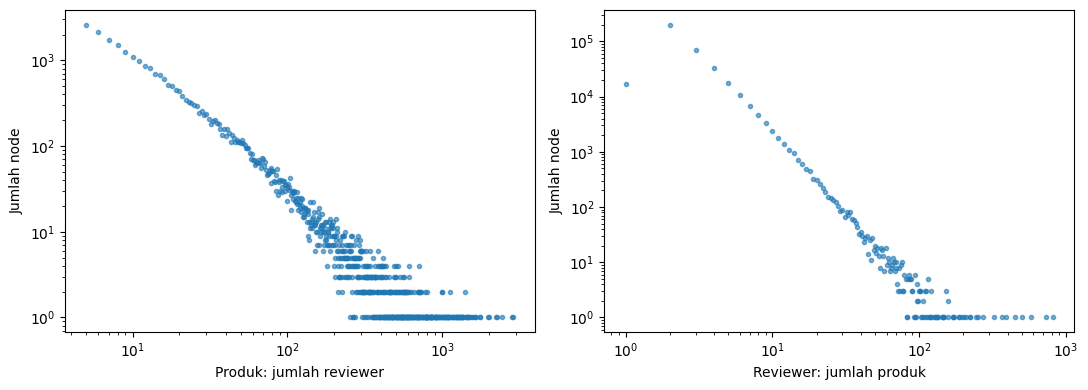

In [16]:
import matplotlib.pyplot as plt, numpy as np, networkx as nx

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, s, t in [(ax[0], prod_pd.n_reviewers, "Produk: jumlah reviewer"),
                (ax[1], user_pd.n_products, "Reviewer: jumlah produk")]:
    vc = s.value_counts().sort_index()
    a.loglog(vc.index, vc.values, ".", alpha=.6)
    a.set_xlabel(t); a.set_ylabel("Jumlah node")
plt.tight_layout(); plt.savefig("a_degree_dist.png", dpi=200); plt.show()

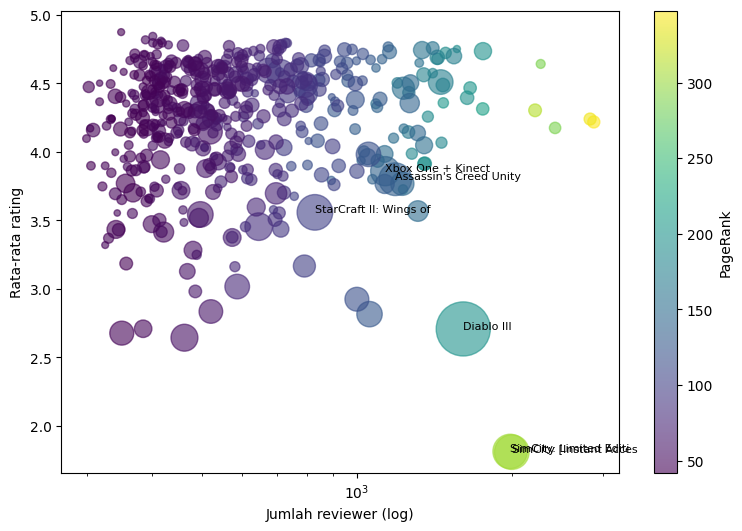

In [17]:
top = prod_pd.nlargest(500, "pagerank")
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(top.n_reviewers, top.mean_rating,
                s=20 + top.votes / top.votes.max() * 1500,
                c=top.pagerank, cmap="viridis", alpha=.6)
ax.set_xscale("log")
ax.set_xlabel("Jumlah reviewer (log)"); ax.set_ylabel("Rata-rata rating")
fig.colorbar(sc, ax=ax, label="PageRank")
for _, r in top.nlargest(6, "votes").iterrows():
    ax.annotate(r.title[:22], (r.n_reviewers, r.mean_rating), fontsize=8)
plt.savefig("b_bubble.png", dpi=200); plt.show()

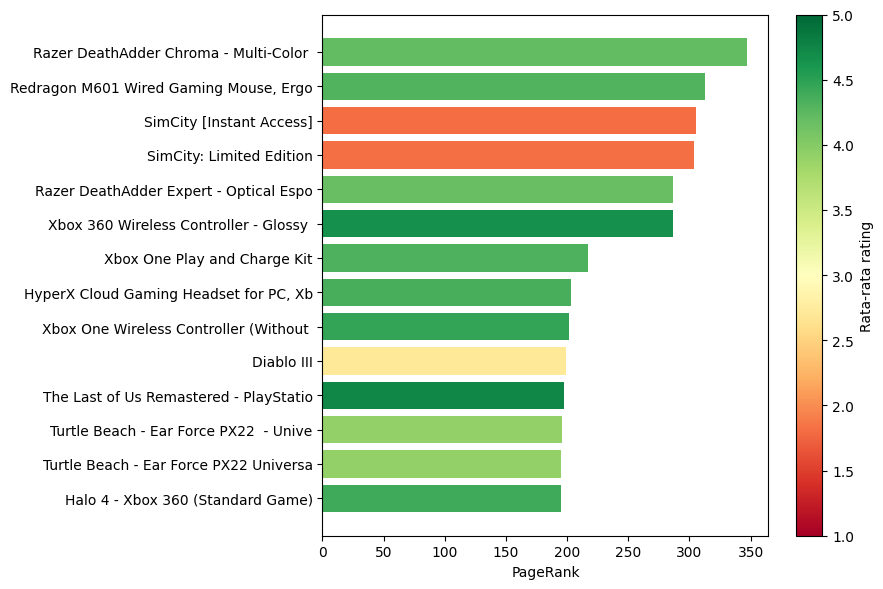

In [18]:
t = prod_pd.nlargest(15, "pagerank").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(t.title.str[:38], t.pagerank, color=plt.cm.RdYlGn((t.mean_rating - 1) / 4))
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(1, 5))
fig.colorbar(sm, ax=ax, label="Rata-rata rating")
ax.set_xlabel("PageRank")
plt.tight_layout(); plt.savefig("c_top_produk.png", dpi=200); plt.show()

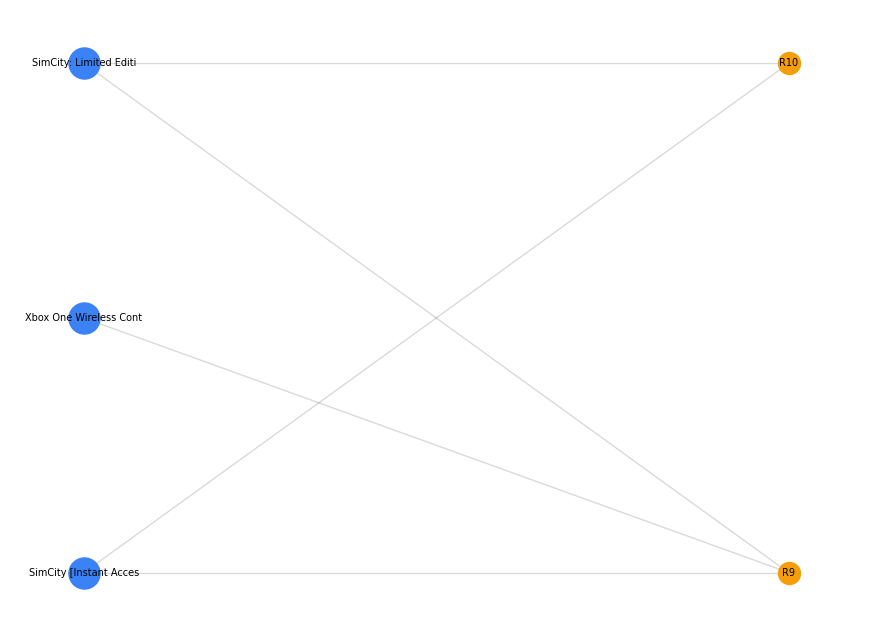

In [24]:
top_p = list(prod_pd.nlargest(10, "pagerank")["id"])
top_u = list(user_pd.nlargest(15, "pagerank")["id"])
sub = (edges.filter(F.col("dst").isin(top_p) & F.col("src").isin(top_u))
            .select("src", "dst").toPandas())

B = nx.from_pandas_edgelist(sub, "src", "dst")
prods = [n for n in B if n.startswith("P_")]
pos = nx.bipartite_layout(B, prods)

tmap = dict(zip(prod_pd.id, prod_pd.title))
alias = {u: f"R{i+1}" for i, u in enumerate(top_u)}          # alias demi privasi (Bab 3.3)
pr = dict(zip(pd.concat([prod_pd.id, user_pd.id]), pd.concat([prod_pd.pagerank, user_pd.pagerank]))) \
     if 'pd' in globals() else {}
labels = {n: (tmap[n][:22] if n.startswith("P_") else alias[n]) for n in B}

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(B, pos, alpha=.15, ax=ax)
nx.draw_networkx_nodes(B, pos, nodelist=prods, node_color="#3b82f6", node_size=500, ax=ax)
nx.draw_networkx_nodes(B, pos, nodelist=[n for n in B if n not in prods],
                       node_color="#f59e0b", node_size=250, ax=ax)
nx.draw_networkx_labels(B, pos, labels, font_size=7, ax=ax)
ax.axis("off"); plt.savefig("d_bipartit.png", dpi=200); plt.show()

In [30]:
user_pd.columns

Index(['id', 'n_products', 'votes', 'mean_rating', 'pagerank',
       'vote_per_product'],
      dtype='object')

In [29]:
user_full.printSchema()

root
 |-- id: string (nullable = true)
 |-- n_products: long (nullable = true)
 |-- votes: long (nullable = true)
 |-- mean_rating: double (nullable = true)
 |-- pagerank: double (nullable = true)



In [31]:
user_pd = user_full.toPandas()

print(user_pd.columns)

Index(['id', 'n_products', 'votes', 'mean_rating', 'pagerank'], dtype='object')


In [33]:
# Top products
top_p = list(
    prod_pd.nlargest(5, "pagerank")["id"]
)

# User yang terhubung dengan top products
candidate_users = (
    edges
    .filter(F.col("dst").isin(top_p))
    .select("src")
    .distinct()
)

candidate_users_pd = candidate_users.toPandas()

# Ambil top 10 user berdasarkan PageRank
top_u = list(
    user_pd[
        user_pd["id"].isin(candidate_users_pd["src"])
    ]
    .nlargest(10, "pagerank")["id"]
)

print("Products:", len(top_p))
print("Users:", len(top_u))

[Stage 151:=============================================>           (4 + 1) / 5]

Products: 5
Users: 10


In [34]:
sub = (
    edges
    .filter(
        F.col("dst").isin(top_p) &
        F.col("src").isin(top_u)
    )
    .select("src", "dst")
    .dropDuplicates()
    .toPandas()
)

print("Edges:", len(sub))
sub.head()

[Stage 174:=============================================>           (4 + 1) / 5]

Edges: 16


,src,dst
0,U_A3MWMO2IOQDWBJ,P_B00HTK1NCS
1,U_A74TA8X5YQ7NE,P_B007FTE2VW
2,U_A32O98PFC3OP7K,P_B00HTK1NCS
3,U_A2F6MNRST15EF7,P_B00JF63SQI
4,U_AWPN47SSWK1JV,P_B00HTK1NCS


Nodes: 15
Products: 5
Users: 10


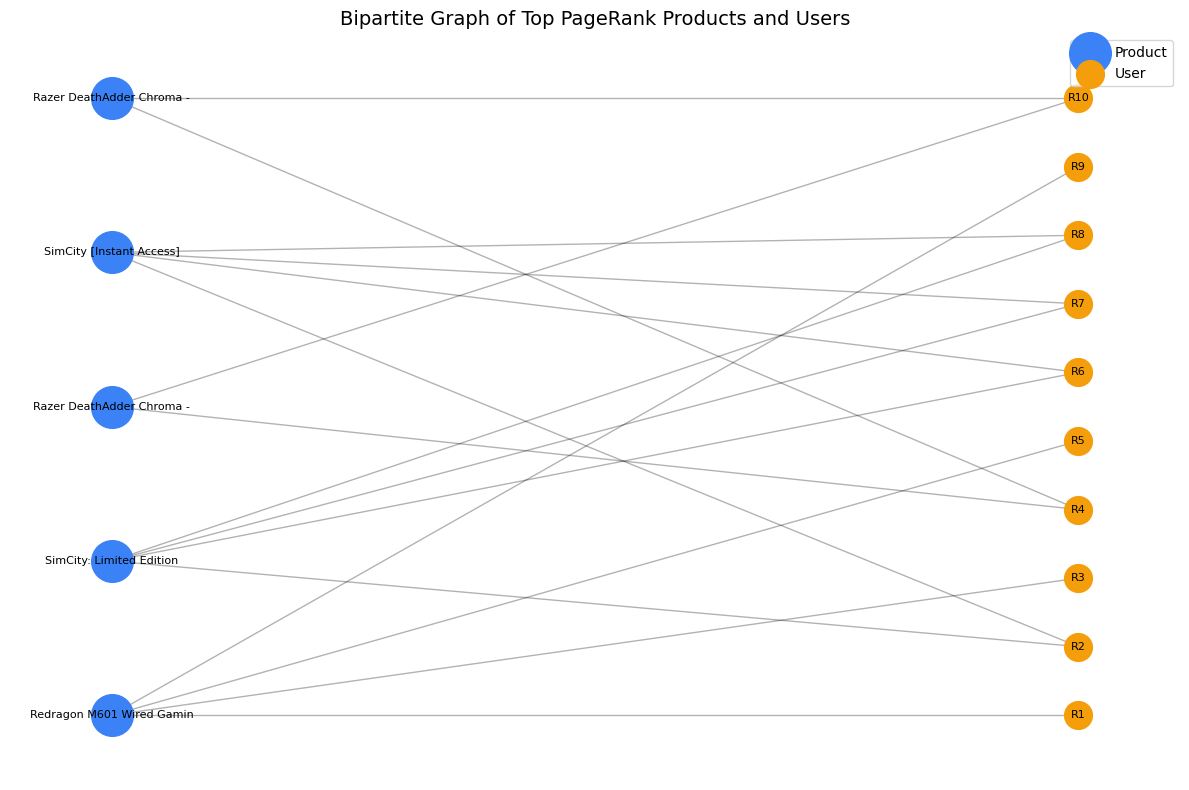

In [35]:
import networkx as nx
import matplotlib.pyplot as plt

# Buat NetworkX graph
B = nx.from_pandas_edgelist(
    sub,
    source="src",
    target="dst"
)

# Pisahkan node user dan product
prods = [n for n in B.nodes if n.startswith("P_")]
users = [n for n in B.nodes if n.startswith("U_")]

print("Nodes:", len(B.nodes))
print("Products:", len(prods))
print("Users:", len(users))


# Layout bipartite
pos = nx.bipartite_layout(
    B,
    prods
)


# Buat label
tmap = dict(zip(prod_pd.id, prod_pd.title))

labels = {}

for n in B.nodes:
    if n.startswith("P_"):
        labels[n] = tmap.get(n, n)[:25]   # judul produk
    else:
        # anonymize user
        labels[n] = f"R{users.index(n)+1}"


# Draw
plt.figure(figsize=(12, 8))

# Edges
nx.draw_networkx_edges(
    B,
    pos,
    alpha=0.3,
    width=1
)

# Product nodes
nx.draw_networkx_nodes(
    B,
    pos,
    nodelist=prods,
    node_color="#3b82f6",
    node_size=900,
    label="Product"
)

# User nodes
nx.draw_networkx_nodes(
    B,
    pos,
    nodelist=users,
    node_color="#f59e0b",
    node_size=400,
    label="User"
)

# Labels
nx.draw_networkx_labels(
    B,
    pos,
    labels,
    font_size=8
)


plt.title(
    "Bipartite Graph of Top PageRank Products and Users",
    fontsize=14
)

plt.legend()
plt.axis("off")
plt.tight_layout()

plt.savefig(
    "bipartite_pagerank_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Proyeksi dan Pembuatan Komunitas Produk - Produk

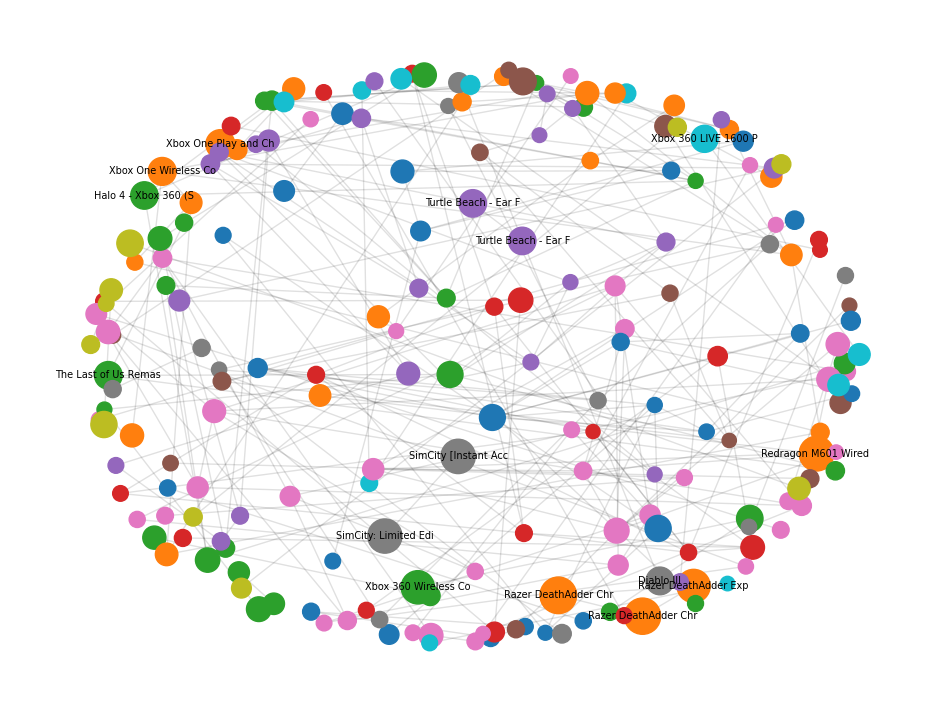

0 5 ['Nintendo 3DS Compatible w', 'AmazonBasics Carrying Cas', 'HORI Screen Protective Fi', 'Nintendo New 3DS XL - Bla']
1 2 ['Destiny - Standard Editio', 'Call of Duty: Advanced Wa']
2 2 ['SADES Spirit Wolf 7.1 Sur', 'SADES Spirit Wolf 7.1 Sur']
3 3 ['Razer BlackWidow Chroma: ', 'RAZER MAMBA TOURNAMENT ED', 'Razer Firefly Chroma Hard']
4 13 ['New Super Mario Bros. Wii', 'Wii', 'Super Smash Bros. Brawl', 'Wii Fit Plus with Balance']
5 13 ['Xbox One Wireless Control', 'Nyko Dual Charge Base Hig', 'Xbox One + Kinect', 'Halo: The Master Chief Co']
6 2 ['Redragon M601 Wired Gamin', 'Redragon K552 RED LED Bac']
7 3 ['Xbox One Play and Charge ', 'Xbox One Media Remote', 'Nyko Intercooler Stand - ']
8 3 ['Razer DeathAdder Chroma -', 'Razer DeathAdder Chroma -', 'Razer DeathAdder Expert -']
9 3 ['Extreme 3D Pro Joystick f', 'Thrustmaster T-Flight Hot', ' Microsoft Flight Simulat']
10 2 ['Microsoft Xbox Wireless A', 'Microsoft Xbox One Contro']
11 2 ['Pok&eacute;mon Moon - Nin', 'Pok&eacute;mon

In [36]:
import pandas as pd

topN = list(prod_pd.nlargest(300, "n_reviewers")["id"])
e_top = edges.filter(F.col("dst").isin(topN)).select("src", "dst")

# batasi super-reviewer (>100 produk) supaya tidak menghubungkan semua produk
ok_u = e_top.groupBy("src").count().filter("count BETWEEN 2 AND 100").select("src")
e_top = e_top.join(ok_u, "src").cache()

d = e_top.groupBy("dst").count().toPandas()
dp = dict(zip(d.dst, d["count"]))

a, b = e_top.alias("a"), e_top.alias("b")
pairs = (a.join(b, (F.col("a.src") == F.col("b.src")) & (F.col("a.dst") < F.col("b.dst")))
          .groupBy(F.col("a.dst").alias("p1"), F.col("b.dst").alias("p2"))
          .agg(F.count("*").alias("shared")).toPandas())
pairs["jaccard"] = pairs.shared / (pairs.p1.map(dp) + pairs.p2.map(dp) - pairs.shared)

G = nx.from_pandas_edgelist(pairs[pairs.jaccard >= 0.05], "p1", "p2", edge_attr="jaccard")
comm = nx.community.louvain_communities(G, weight="jaccard", seed=42)
cid = {n: i for i, c in enumerate(comm) for n in c}
prank = dict(zip(prod_pd.id, prod_pd.pagerank))

pos = nx.spring_layout(G, weight="jaccard", seed=42, k=0.4)
fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, alpha=.12, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=[cid[n] for n in G], cmap="tab10",
                       node_size=[prank[n] * 2 for n in G], ax=ax)
big = sorted(G, key=prank.get, reverse=True)[:15]
nx.draw_networkx_labels(G, pos, {n: tmap[n][:20] for n in big}, font_size=7, ax=ax)
ax.axis("off"); plt.savefig("e_proyeksi_produk.png", dpi=200); plt.show()

# interpretasi tiap klaster dan produk jembatan
for i, c in enumerate(comm):
    print(i, len(c), [tmap[n][:25] for n in sorted(c, key=prank.get, reverse=True)[:4]])
bt = nx.betweenness_centrality(G)
print(sorted(((tmap[n][:30], round(v, 3)) for n, v in bt.items()), key=lambda x: -x[1])[:5])